In [30]:
from pathlib import Path
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
for item in Path.cwd().iterdir():
    print(item.name)

print("\nSearching for the Excel file:")
for path in Path.cwd().parent.rglob("online_retail_II.xlsx"):
    print(path)

Current working directory:
c:\Users\anush\Customer-Journey-Reconstruction-Engine\src

Files and folders here:
clean_data.ipynb

Searching for the Excel file:
c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\raw\online_retail_II.xlsx


In [31]:

from pathlib import Path
import time
import pandas as pd


# Notebook is running from the src folder
ROOT = Path.cwd().parent

RAW_FILE = ROOT / "data" / "raw" / "online_retail_II.xlsx"

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Excel file:", RAW_FILE)
print("File exists:", RAW_FILE.exists())
print("Processed folder:", PROCESSED_DIR)
# ==================================================
# 2. LOAD DATA (USE CSV AFTER FIRST CONVERSION)
# ==================================================

start = time.perf_counter()

CSV_FILES = [
    RAW_DIR / "retail_2009_2010.csv",
    RAW_DIR / "retail_2010_2011.csv",
]

if all(path.exists() for path in CSV_FILES):
    print("\nLoading existing CSV files...")

    year_1 = pd.read_csv(CSV_FILES[0])
    year_2 = pd.read_csv(CSV_FILES[1])

else:
    print("\nReading Excel workbook. First run may take a while...")

    excel = pd.ExcelFile(RAW_FILE, engine="openpyxl")

    print("Sheets found:", excel.sheet_names)

    expected_sheets = [
        "Year 2009-2010",
        "Year 2010-2011",
    ]

    missing_sheets = [
        name for name in expected_sheets
        if name not in excel.sheet_names
    ]

    if missing_sheets:
        raise ValueError(
            f"Expected sheets not found: {missing_sheets}"
        )

    year_1 = pd.read_excel(
        excel, sheet_name="Year 2009-2010"
    )
    year_2 = pd.read_excel(
        excel, sheet_name="Year 2010-2011"
    )

    year_1.to_csv(CSV_FILES[0], index=False)
    year_2.to_csv(CSV_FILES[1], index=False)

    print("Saved CSV copies for future runs.")

# Record which year each row came from
year_1["source_year"] = "2009-2010"
year_2["source_year"] = "2010-2011"

# Combine both years
df = pd.concat(
    [year_1, year_2],
    ignore_index=True
)

initial_rows = len(df)

print(f"\nCombined rows: {initial_rows:,}")
print(f"Load time: {time.perf_counter() - start:.2f} seconds")

# ==================================================
# 3. STANDARDIZE COLUMN NAMES
# ==================================================

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

required_columns = [
    "invoice",
    "stockcode",
    "quantity",
    "invoicedate",
    "price",
    "customer_id",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing expected columns: {missing_columns}"
    )

# ==================================================
# 4. CONVERT DATA TYPES
# ==================================================

df["invoice"] = df["invoice"].astype("string").str.strip()
df["stockcode"] = df["stockcode"].astype("string").str.strip()

if "description" in df.columns:
    df["description"] = df["description"].astype("string").str.strip()

if "country" in df.columns:
    df["country"] = df["country"].astype("string").str.strip()

df["customer_id"] = pd.to_numeric(
    df["customer_id"], errors="coerce"
).astype("Int64")

df["invoicedate"] = pd.to_datetime(
    df["invoicedate"], errors="coerce"
)

df["quantity"] = pd.to_numeric(
    df["quantity"], errors="coerce"
)

df["price"] = pd.to_numeric(
    df["price"], errors="coerce"
)

# ==================================================
# 5. FLAG DATA QUALITY ISSUES
# ==================================================

df["is_cancellation_invoice"] = (
    df["invoice"].str.startswith("C", na=False)
)

df["is_return_quantity"] = df["quantity"] < 0

df["is_invalid_date"] = df["invoicedate"].isna()

df["is_nonpositive_quantity"] = df["quantity"] <= 0

df["is_nonpositive_price"] = df["price"] <= 0

df["line_amount"] = df["quantity"] * df["price"]

# Detect duplicates using original business columns,
# excluding generated flags and source-sheet metadata.
original_columns = [
    col for col in df.columns
    if col not in [
        "source_year",
        "is_cancellation_invoice",
        "is_return_quantity",
        "is_invalid_date",
        "is_nonpositive_quantity",
        "is_nonpositive_price",
        "line_amount",
    ]
]

df["is_exact_duplicate"] = df.duplicated(
    subset=original_columns,
    keep="first",
)

# Save all records with quality flags intact
all_path = PROCESSED_DIR / "transactions_all.parquet"
df.to_parquet(all_path, index=False)

# ==================================================
# 6. BUILD CUSTOMER PURCHASE DATASET
# ==================================================

valid_purchase = (
    df["customer_id"].notna()
    & df["invoicedate"].notna()
    & df["invoice"].notna()
    & df["stockcode"].notna()
    & ~df["is_cancellation_invoice"]
    & (df["quantity"] > 0)
    & (df["price"] > 0)
)

# Create a purchase-only dataset.
# Keep the full dataset above for auditing.
purchase_df = df.loc[valid_purchase].copy()

# Exclude exact duplicates from the analysis table.
# The duplicate flags remain available in transactions_all.
purchase_df = purchase_df.loc[
    ~purchase_df["is_exact_duplicate"]
].copy()

purchase_df["revenue"] = (
    purchase_df["quantity"] * purchase_df["price"]
)

purchase_df["invoice_month"] = (
    purchase_df["invoicedate"]
    .dt.to_period("M")
    .astype(str)
)

purchase_df["invoice_day"] = (
    purchase_df["invoicedate"].dt.date
)

purchase_path = (
    PROCESSED_DIR / "customer_transactions.parquet"
)

purchase_df.to_parquet(
    purchase_path,
    index=False
)

# ==================================================
# 7. CREATE CLEANING SUMMARY
# ==================================================

summary_rows = [
    ("initial_rows", len(df)),
    ("missing_customer_id", int(df["customer_id"].isna().sum())),
    ("missing_dates", int(df["is_invalid_date"].sum())),
    ("cancellation_invoice_rows", int(df["is_cancellation_invoice"].sum())),
    ("negative_quantity_rows", int((df["quantity"] < 0).sum())),
    ("zero_quantity_rows", int((df["quantity"] == 0).sum())),
    ("zero_price_rows", int((df["price"] == 0).sum())),
    ("negative_price_rows", int((df["price"] < 0).sum())),
    ("exact_duplicate_rows_flagged", int(df["is_exact_duplicate"].sum())),
    ("rows_passing_purchase_filters", int(valid_purchase.sum())),
    ("customer_purchase_rows_after_deduplication", len(purchase_df)),
    ("unique_customers", int(purchase_df["customer_id"].nunique())),
    ("unique_invoices", int(purchase_df["invoice"].nunique())),
    ("unique_products", int(purchase_df["stockcode"].nunique())),
    ("purchase_revenue", round(purchase_df["revenue"].sum(), 2)),
]

summary = pd.DataFrame(
    summary_rows,
    columns=["metric", "value"]
)

summary_path = PROCESSED_DIR / "cleaning_summary.csv"
summary.to_csv(summary_path, index=False)

# ==================================================
# 8. PRINT RESULTS
# ==================================================

print("\n" + "=" * 55)
print("CLEANING PIPELINE COMPLETED")
print("=" * 55)

print(f"Original rows: {len(df):,}")
print(f"Purchase rows: {len(purchase_df):,}")
print(f"Unique customers: {purchase_df['customer_id'].nunique():,}")
print(f"Unique invoices: {purchase_df['invoice'].nunique():,}")
print(f"Unique products: {purchase_df['stockcode'].nunique():,}")
print(f"Purchase revenue: {purchase_df['revenue'].sum():,.2f}")

print("\nSaved outputs:")
print(all_path)
print(purchase_path)
print(summary_path)

print("\nCleaning summary:")
print(summary.to_string(index=False))


Project root: c:\Users\anush\Customer-Journey-Reconstruction-Engine
Excel file: c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\raw\online_retail_II.xlsx
File exists: True
Processed folder: c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\processed

Reading Excel workbook. First run may take a while...
Sheets found: ['Year 2009-2010', 'Year 2010-2011']
Saved CSV copies for future runs.

Combined rows: 1,067,371
Load time: 75.34 seconds

CLEANING PIPELINE COMPLETED
Original rows: 1,067,371
Purchase rows: 779,425
Unique customers: 5,878
Unique invoices: 36,969
Unique products: 4,631
Purchase revenue: 17,374,804.27

Saved outputs:
c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\processed\transactions_all.parquet
c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\processed\customer_transactions.parquet
c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\processed\cleaning_summary.csv

Cleaning summary:
                                    metri

In [32]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"

print("Processed files:")
for file in PROCESSED_DIR.iterdir():
    print(file.name)

Processed files:
cleaning_summary.csv
customer_transactions.parquet
transactions_all.parquet


In [33]:
df = pd.read_parquet(
    PROCESSED_DIR / "customer_transactions.parquet"
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

Dataset shape: (779425, 19)

Columns:
['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country', 'source_year', 'is_cancellation_invoice', 'is_return_quantity', 'is_invalid_date', 'is_nonpositive_quantity', 'is_nonpositive_price', 'line_amount', 'is_exact_duplicate', 'revenue', 'invoice_month', 'invoice_day']

First 5 rows:


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_year,is_cancellation_invoice,is_return_quantity,is_invalid_date,is_nonpositive_quantity,is_nonpositive_price,line_amount,is_exact_duplicate,revenue,invoice_month,invoice_day
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,2009-2010,False,False,False,False,False,83.4,False,83.4,2009-12,2009-12-01
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-2010,False,False,False,False,False,81.0,False,81.0,2009-12,2009-12-01
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-2010,False,False,False,False,False,81.0,False,81.0,2009-12,2009-12-01
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,2009-2010,False,False,False,False,False,100.8,False,100.8,2009-12,2009-12-01
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,2009-2010,False,False,False,False,False,30.0,False,30.0,2009-12,2009-12-01



Missing values:


invoice                    0
stockcode                  0
description                0
quantity                   0
invoicedate                0
price                      0
customer_id                0
country                    0
source_year                0
is_cancellation_invoice    0
is_return_quantity         0
is_invalid_date            0
is_nonpositive_quantity    0
is_nonpositive_price       0
line_amount                0
is_exact_duplicate         0
revenue                    0
invoice_month              0
invoice_day                0
dtype: int64

In [34]:
print("Unique customers:", df["customer_id"].nunique())
print("Unique invoices:", df["invoice"].nunique())
print("Unique products:", df["stockcode"].nunique())
print("Date range:", df["invoicedate"].min(),
      "to", df["invoicedate"].max())

print("\nRevenue:", round(df["line_amount"].sum(), 2))

print("\nTop 10 countries by transaction rows:")
display(df["country"].value_counts().head(10))

print("\nTop 10 products by quantity sold:")
display(
    df.groupby("description")["quantity"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

Unique customers: 5878
Unique invoices: 36969
Unique products: 4631
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00

Revenue: 17374804.27

Top 10 countries by transaction rows:


country
United Kingdom    700388
Germany            16432
EIRE               15565
France             13511
Netherlands         5085
Spain               3662
Belgium             3055
Switzerland         3005
Portugal            2356
Australia           1789
Name: count, dtype: Int64


Top 10 products by quantity sold:


description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     105185
WHITE HANGING HEART T-LIGHT HOLDER     91757
PAPER CRAFT , LITTLE BIRDIE            80995
ASSORTED COLOUR BIRD ORNAMENT          78234
MEDIUM CERAMIC TOP STORAGE JAR         77916
JUMBO BAG RED RETROSPOT                74224
BROCADE RING PURSE                     70082
PACK OF 60 PINK PAISLEY CAKE CASES     54592
60 TEATIME FAIRY CAKE CASES            52828
PACK OF 72 RETRO SPOT CAKE CASES       45129
Name: quantity, dtype: int64

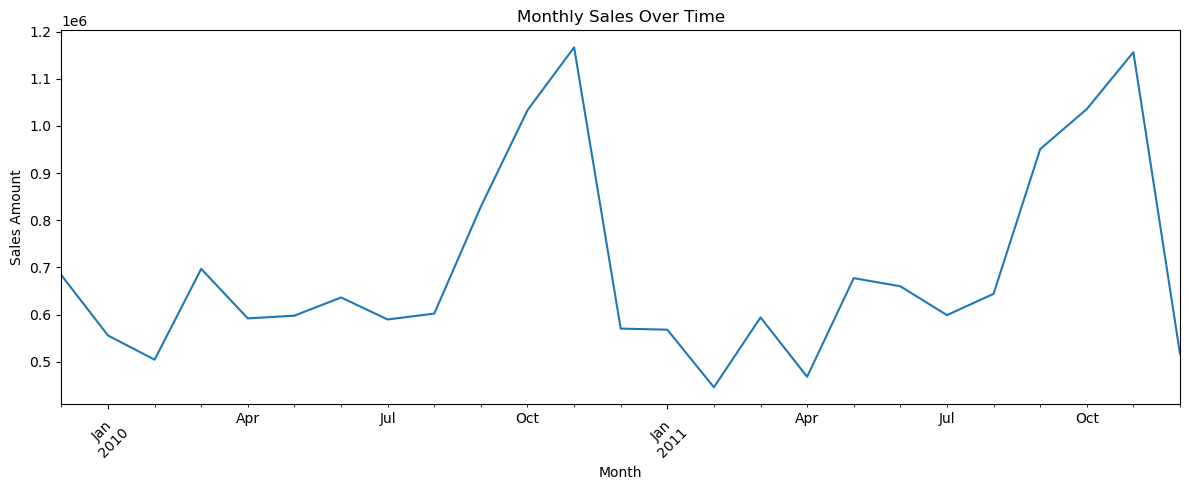

In [35]:
import matplotlib.pyplot as plt

df["invoicedate"] = pd.to_datetime(df["invoicedate"])

monthly_sales = (
    df.set_index("invoicedate")["line_amount"]
      .resample("MS")
      .sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.plot()
plt.title("Monthly Sales Over Time")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
customer_orders = (
    df.groupby("customer_id")["invoice"]
      .nunique()
)

repeat_customers = (customer_orders >= 2).sum()
total_customers = customer_orders.count()

print("Total customers:", total_customers)
print("Customers with 2+ invoices:", repeat_customers)
print(
    "Repeat customer rate:",
    round(100 * repeat_customers / total_customers, 2),
    "%"
)

Total customers: 5878
Customers with 2+ invoices: 4255
Repeat customer rate: 72.39 %


Customers with repeat orders: 4255

Days between orders:
count    31091.000000
mean        51.686656
std         75.788911
min          0.000000
25%          6.983333
50%         24.743056
75%         61.810417
90%        134.875694
max        714.152083
Name: days_since_previous_order, dtype: float64


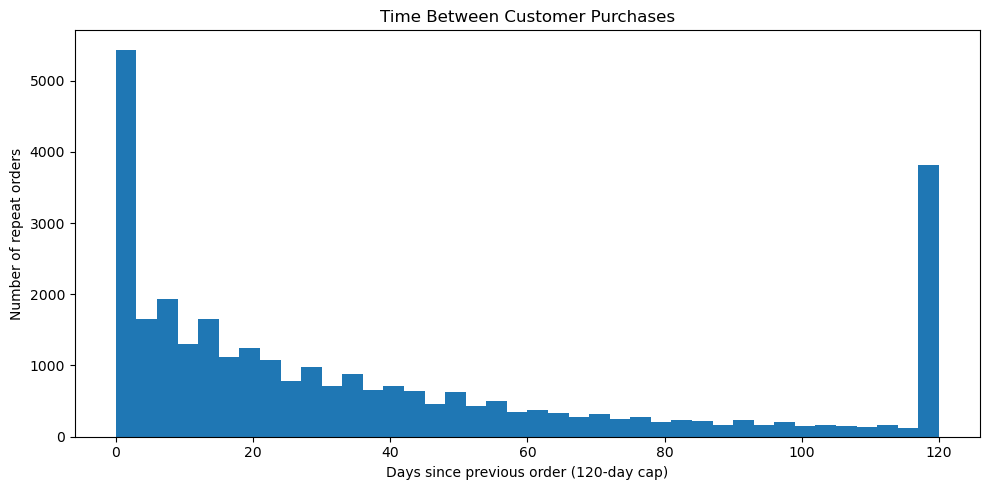

In [37]:

import pandas as pd
import matplotlib.pyplot as plt

# One row per customer per invoice
orders = (
    df.groupby(["customer_id", "invoice"], as_index=False)
      .agg(
          order_date=("invoicedate", "min"),
          order_value=("line_amount", "sum")
      )
)

orders = orders.sort_values(["customer_id", "order_date"])

# Time between consecutive orders for each customer
orders["days_since_previous_order"] = (
    orders.groupby("customer_id")["order_date"]
          .diff()
          .dt.total_seconds()
          .div(86400)
)

# Keep only customers with at least two orders
gaps = orders["days_since_previous_order"].dropna()

print("Customers with repeat orders:",
      orders.loc[orders["days_since_previous_order"].notna(),
                 "customer_id"].nunique())

print("\nDays between orders:")
print(gaps.describe(percentiles=[0.25, 0.5, 0.75, 0.9]))

plt.figure(figsize=(10, 5))
plt.hist(gaps.clip(upper=120), bins=40)
plt.title("Time Between Customer Purchases")
plt.xlabel("Days since previous order (120-day cap)")
plt.ylabel("Number of repeat orders")
plt.tight_layout()
plt.show()


In [38]:

customer_summary = (
    orders.groupby("customer_id")
          .agg(
              total_orders=("invoice", "nunique"),
              total_spend=("order_value", "sum"),
              average_order_value=("order_value", "mean"),
              first_purchase=("order_date", "min"),
              last_purchase=("order_date", "max")
          )
)

customer_summary["customer_lifetime_days"] = (
    customer_summary["last_purchase"]
    - customer_summary["first_purchase"]
).dt.days

print("Customer summary:")
display(customer_summary.describe().round(2))

print("\nCustomers with the most orders:")
display(customer_summary.sort_values(
    "total_orders", ascending=False
).head(10))

print("\nCustomers with the highest spending:")
display(customer_summary.sort_values(
    "total_spend", ascending=False
).head(10))


Customer summary:


,total_orders,total_spend,average_order_value,first_purchase,last_purchase,customer_lifetime_days
count,5878.00,5878.00,5878.00,5878,5878,5878.00
mean,6.29,2955.90,385.18,2010-08-22 06:57:33.297039616,2011-05-22 16:19:59.418169344,273.02
min,1.00,2.95,2.95,2009-12-01 07:45:00,2009-12-01 09:55:00,0.00
25%,1.00,342.28,176.68,2010-02-09 14:01:15,2010-11-25 10:24:45,0.00
50%,3.00,867.74,279.24,2010-06-27 13:31:30,2011-09-05 11:59:00,220.50
75%,7.00,2248.31,414.90,2011-01-30 14:30:15,2011-11-14 11:31:15,511.00
max,398.00,580987.04,84236.25,2011-12-09 12:16:00,2011-12-09 12:50:00,738.00
std,13.01,14440.85,1214.29,NaN,NaN,258.81



Customers with the most orders:


,total_orders,total_spend,average_order_value,first_purchase,last_purchase,customer_lifetime_days
customer_id,,,,,,
14911,398,291420.81,732.213090,2009-12-01 11:41:00,2011-12-08 15:54:00,737
12748,336,53539.64,159.344167,2009-12-04 17:31:00,2011-12-09 12:20:00,734
17841,211,68545.25,324.859005,2009-12-02 15:41:00,2011-12-08 12:07:00,735
15311,208,114966.42,552.723173,2009-12-01 11:21:00,2011-12-09 12:00:00,738
13089,203,113416.91,558.703990,2009-12-02 15:44:00,2011-12-07 09:02:00,734
14606,192,29951.37,155.996719,2009-12-03 12:40:00,2011-12-08 19:28:00,735
14156,156,313437.62,2009.215513,2009-12-01 12:30:00,2011-11-30 10:54:00,728
17850,155,51208.87,330.379806,2009-12-05 12:28:00,2010-12-02 15:27:00,362
14646,151,528602.52,3500.678940,2009-12-02 16:52:00,2011-12-08 12:12:00,735



Customers with the highest spending:


,total_orders,total_spend,average_order_value,first_purchase,last_purchase,customer_lifetime_days
customer_id,,,,,,
18102,145,580987.04,4006.807172,2009-12-01 09:24:00,2011-12-09 11:50:00,738
14646,151,528602.52,3500.678940,2009-12-02 16:52:00,2011-12-08 12:12:00,735
14156,156,313437.62,2009.215513,2009-12-01 12:30:00,2011-11-30 10:54:00,728
14911,398,291420.81,732.213090,2009-12-01 11:41:00,2011-12-08 15:54:00,737
17450,51,244784.25,4799.691176,2010-09-27 16:59:00,2011-12-01 13:29:00,429
13694,143,195640.69,1368.116713,2009-12-04 15:26:00,2011-12-06 09:32:00,731
17511,60,172132.87,2868.881167,2009-12-02 10:52:00,2011-12-07 10:12:00,734
16446,2,168472.50,84236.250000,2011-05-18 09:52:00,2011-12-09 09:15:00,204
16684,55,147142.77,2675.323091,2009-12-07 12:56:00,2011-12-05 14:06:00,728


In [39]:

# `gaps` is the days_since_previous_order series from your previous cell.

print("Purchase gap percentiles:")
print(
    gaps.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
)

print("\nShare of repeat orders with a gap:")
for days in [7, 30, 60, 90, 120]:
    share = (gaps > days).mean() * 100
    print(f"More than {days:3} days: {share:.2f}%")


Purchase gap percentiles:
0.10      0.013194
0.25      6.983333
0.50     24.743056
0.75     61.810417
0.90    134.875694
0.95    206.426736
0.99    368.740764
Name: days_since_previous_order, dtype: float64

Share of repeat orders with a gap:
More than   7 days: 74.75%
More than  30 days: 44.78%
More than  60 days: 25.58%
More than  90 days: 17.04%
More than 120 days: 11.80%


In [ ]:

# `orders` contains one row per customer per invoice.
# `features` is your existing customer-level feature table.

orders = orders.sort_values(["customer_id", "order_date"]).copy()

orders["gap_days"] = (
    orders.groupby("customer_id")["order_date"]
          .diff()
          .dt.total_seconds()
          .div(86400)
)

gap_features = (
    orders.groupby("customer_id")["gap_days"]
          .agg(
              average_gap_days="mean",
              median_gap_days="median"
          )
)

features = features.drop(
    columns=["purchase_frequency"],
    errors="ignore"
).join(gap_features)

features["orders_per_30_days"] = (
    30 * (features["total_orders"] - 1)
    / features["customer_lifetime_days"].replace(0, float("nan"))
)

print("Feature table shape:", features.shape)
print("\nMissing values:")
print(features.isna().sum())

display(features.head(10))


Feature table shape: (5878, 8)


,total_orders,total_spend,average_order_value,first_purchase,last_purchase,recency_days,customer_lifetime_days,purchase_frequency
customer_id,,,,,,,,
12346,12,77556.46,6463.038333,2009-12-14 08:34:00,2011-01-18 10:01:00,326.117361,400.060417,0.899864
12347,8,4921.53,615.191250,2010-10-31 14:20:00,2011-12-07 15:52:00,2.873611,402.063889,0.596920
12348,5,2019.40,403.880000,2010-09-27 14:59:00,2011-09-25 13:13:00,75.984028,362.926389,0.413307
12349,4,4428.69,1107.172500,2010-04-29 13:20:00,2011-11-21 09:51:00,19.124306,570.854861,0.210211
12350,1,334.40,334.400000,2011-02-02 16:01:00,2011-02-02 16:01:00,310.867361,0.000000,30.000000
12351,1,300.93,300.930000,2010-11-29 15:23:00,2010-11-29 15:23:00,375.893750,0.000000,30.000000
12352,10,2849.84,284.984000,2010-11-12 10:20:00,2011-11-03 14:37:00,36.925694,356.178472,0.842274
12353,2,406.76,203.380000,2010-10-27 12:44:00,2011-05-19 17:47:00,204.793750,204.210417,0.293815
12354,1,1079.40,1079.400000,2011-04-21 13:11:00,2011-04-21 13:11:00,232.985417,0.000000,30.000000


In [41]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"

df = pd.read_parquet(PROCESSED_DIR / "customer_transactions.parquet")
summary = pd.read_csv(PROCESSED_DIR / "cleaning_summary.csv")

print("CLEANING SUMMARY")
display(summary)

print("\nDATA QUALITY CHECKS")
print("Rows:", len(df))
print("Missing customer IDs:", df["customer_id"].isna().sum())
print("Missing invoice dates:", df["invoicedate"].isna().sum())
print("Non-positive quantities:", (df["quantity"] <= 0).sum())
print("Non-positive prices:", (df["price"] <= 0).sum())
print("Duplicate rows:", df.duplicated().sum())
print("Unique customers:", df["customer_id"].nunique())
print("Unique invoices:", df["invoice"].nunique())

assert df["customer_id"].notna().all(), "Missing customer IDs remain"
assert df["invoicedate"].notna().all(), "Missing dates remain"
assert (df["quantity"] > 0).all(), "Invalid quantities remain"
assert (df["price"] > 0).all(), "Invalid prices remain"

print("\nBasic checks passed.")

CLEANING SUMMARY


,metric,value
0,initial_rows,1067371.00
1,missing_customer_id,243007.00
2,missing_dates,0.00
3,cancellation_invoice_rows,19494.00
4,negative_quantity_rows,22950.00
5,zero_quantity_rows,0.00
6,zero_price_rows,6202.00
7,negative_price_rows,5.00
8,exact_duplicate_rows_flagged,34335.00
9,rows_passing_purchase_filters,805549.00



DATA QUALITY CHECKS
Rows: 779425
Missing customer IDs: 0
Missing invoice dates: 0
Non-positive quantities: 0
Non-positive prices: 0
Duplicate rows: 0
Unique customers: 5878
Unique invoices: 36969

Basic checks passed.


In [42]:
from pathlib import Path

ROOT = Path.cwd().parent
REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report = """
# Customer Journey Reconstruction Engine
## Day 1 — Exploratory Data Analysis

### Dataset overview
- Unique customers: 5,878
- Unique invoices: 36,969
- Unique products: 4,631
- Recorded purchase-line value: £17,374,804.27

### Customer behavior
- Customers with at least two invoices: 4,255
- Repeat-customer rate: 72.39%
- Median interval between repeat orders: approximately 24.74 days
- 44.78% of observed repeat-order intervals exceed 30 days.
- 17.04% exceed 90 days.

### Initial observations
- Monthly sales show apparent seasonal peaks near the end of both years.
- The UK accounts for most transaction rows.
- Purchase frequency and spending vary considerably across customers.
- Some customers have exceptionally high order counts or spending.

### Caveats
- These results describe the cleaned dataset and depend on the
  cleaning rules used.
- Repeat purchasing does not necessarily imply long-term loyalty.
- High spending and order counts should be investigated for
  wholesale behavior and outliers.
- Seasonal patterns should be checked against the number of
  recorded days in each month.

### Next step
Build customer features over successive time windows and study
behavioral states and transitions.
"""

report_path = REPORT_DIR / "day1_eda_report.md"
report_path.write_text(report.strip(), encoding="utf-8")

print("Report saved to:", report_path)

Report saved to: c:\Users\anush\Customer-Journey-Reconstruction-Engine\reports\day1_eda_report.md
